# Ontario hourly electricity demand forecasting
Predict the next hour from the previous 24 hours. Compare yesterday's same-hour demand with small LSTM and GRU models using real IESO data from 2022–2023.

Timestamps mark the **start** of each reporting hour: hour 1 becomes 00:00, hour 24 becomes 23:00. Keep IESO's reporting clock without timezone conversion.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/ontario-matplotlib")
%matplotlib inline

from pathlib import Path
from io import StringIO
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

np.random.seed(42)
tf.keras.utils.set_random_seed(42)
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.experimental.enable_op_determinism()
Path("data").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)
plt.rcParams["figure.figsize"] = (12, 4)
print("TensorFlow:", tf.__version__)

2026-11-22 14:01:02.491327: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-22 14:01:02.491391: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-22 14:01:02.492806: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


TensorFlow: 2.15.0


## 1. Load and clean
Read the annual CSVs after their comment lines. Download only when a local copy is missing. Average duplicate timestamps, restore the hourly grid, and interpolate at most three consecutive missing hours. Keep an unfilled copy to check the split boundaries.

In [2]:
frames = []
for year in (2022, 2023):
    path = Path(f"data/PUB_Demand_{year}.csv")
    if not path.exists():
        url = f"http://reports.ieso.ca/public/Demand/PUB_Demand_{year}.csv"
        with urllib.request.urlopen(url, timeout=60) as response:
            text = response.read().decode("utf-8-sig")
        if "Date,Hour,Market Demand,Ontario Demand" not in text[:1000]:
            raise ValueError("IESO did not return a demand CSV")
        path.write_text(text)
    lines = path.read_text(encoding="utf-8-sig").splitlines()
    header = next(i for i, line in enumerate(lines) if line.startswith("Date,Hour,"))
    part = pd.read_csv(StringIO("\n".join(lines[header:])))
    hours = pd.to_numeric(part["Hour"], errors="raise")
    assert hours.between(1, 24).all()
    part["datetime"] = pd.to_datetime(part["Date"]) + pd.to_timedelta(hours - 1, unit="h")
    part["demand_mw"] = pd.to_numeric(part["Ontario Demand"], errors="coerce")
    frames.append(part[["datetime", "demand_mw"]])

raw = pd.concat(frames, ignore_index=True)
duplicates = int(raw["datetime"].duplicated().sum())
unfilled = raw.groupby("datetime")["demand_mw"].mean().sort_index().asfreq("h")
missing = int(unfilled.isna().sum())
demand = unfilled.interpolate(method="time", limit=3, limit_area="inside")
assert demand.notna().all(), "Unfilled or long missing interval: inspect the source data"
assert (demand > 0).all()
demand.to_csv("data/ontario_hourly_demand.csv", index_label="datetime")
print(f"{len(demand):,} hours: {demand.index.min()} to {demand.index.max()}")
print(f"Duplicate hours averaged: {duplicates}; missing hours interpolated: {missing}")
display(demand.head().to_frame())

17,520 hours: 2022-01-01 00:00:00 to 2023-12-31 23:00:00
Duplicate hours averaged: 0; missing hours interpolated: 0


,demand_mw
datetime,
2022-01-01 00:00:00,13543.0
2022-01-01 01:00:00,13254.0
2022-01-01 02:00:00,12683.0
2022-01-01 03:00:00,12491.0
2022-01-01 04:00:00,12493.0


## 2. Quick EDA

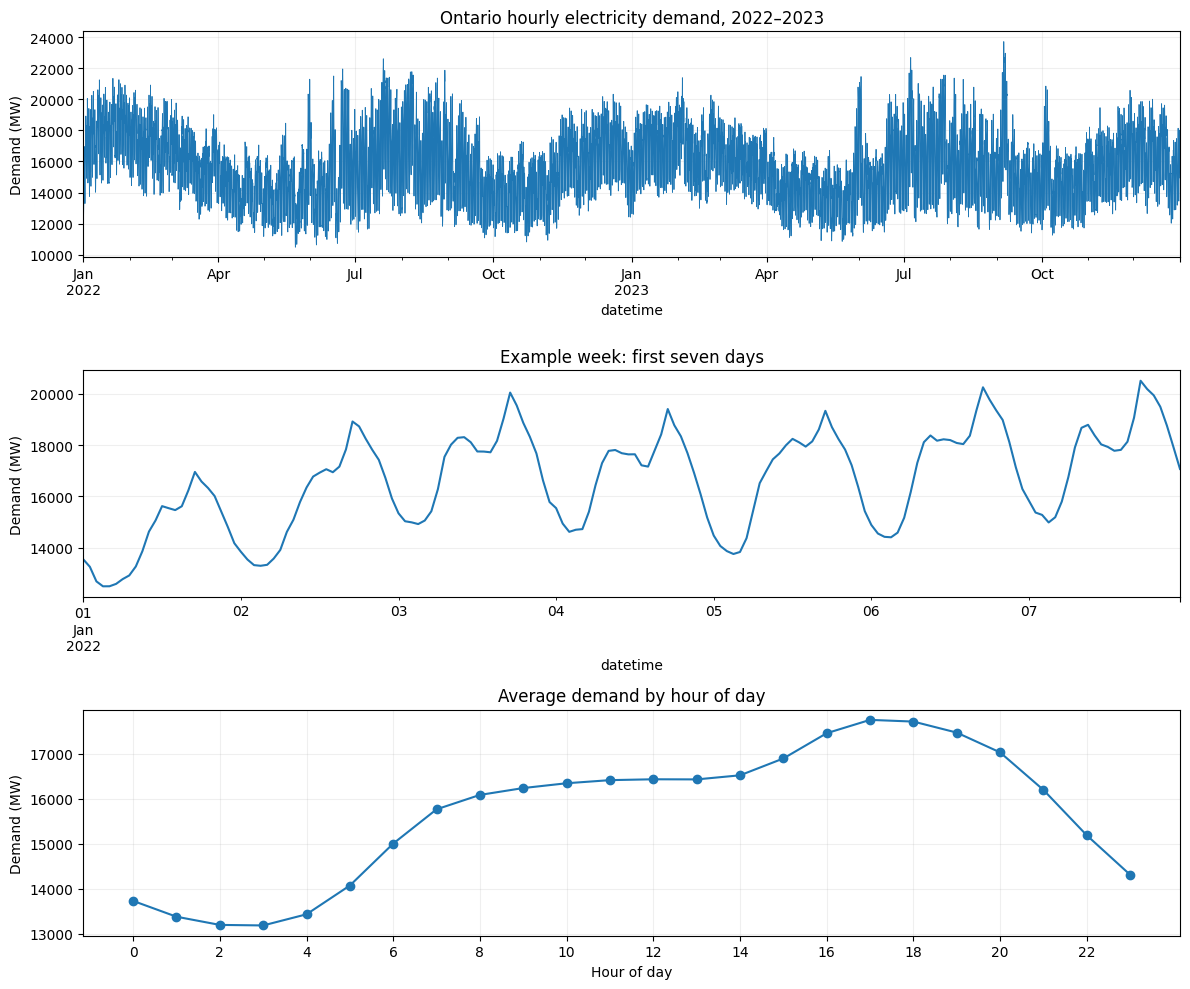

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
demand.plot(ax=axes[0], title="Ontario hourly electricity demand, 2022–2023", linewidth=0.6)
demand.iloc[:168].plot(ax=axes[1], title="Example week: first seven days")
demand.groupby(demand.index.hour).mean().plot(ax=axes[2], marker="o", title="Average demand by hour of day")
axes[2].set_xticks(range(0, 24, 2))
axes[2].set_xlabel("Hour of day")
for ax in axes:
    ax.set_ylabel("Demand (MW)")
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig("results/eda.png", dpi=150)
plt.show()

## 3. Time split, scaling and 24-hour windows
The first 80% of hours form the training part; its last 10% is validation. Fit the scaler on the earlier fitting hours only. Assign each window by its **target timestamp**, so validation/test can use already observed earlier demand. This is a rolling one-hour-ahead evaluation, not a recursive week-ahead forecast. No shuffling.

In [4]:
test_start = int(len(demand) * 0.8)
val_start = int(test_start * 0.9)
# A missing value at either boundary could interpolate across the split.
for boundary in (val_start, test_start):
    assert unfilled.iloc[boundary - 1:boundary + 1].notna().all()
scaler = MinMaxScaler()
scaler.fit(demand.iloc[:val_start].to_numpy().reshape(-1, 1))
scaled = scaler.transform(demand.to_numpy().reshape(-1, 1)).astype("float32")

window = 24
X = np.array([scaled[i-window:i] for i in range(window, len(scaled))])
y = scaled[window:]
target_positions = np.arange(window, len(demand))
train_mask = target_positions < val_start
val_mask = (target_positions >= val_start) & (target_positions < test_start)
test_mask = target_positions >= test_start
X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]
test_times = demand.index[target_positions[test_mask]]
print(f"Windows: train={len(X_train):,}, validation={len(X_val):,}, test={len(X_test):,}")
print("Validation starts:", demand.index[val_start])
print("Test starts:", demand.index[test_start])
print("Window shape:", X_train.shape)

Windows: train=12,590, validation=1,402, test=3,504
Validation starts: 2023-06-10 14:00:00
Test starts: 2023-08-08 00:00:00
Window shape: (12590, 24, 1)


## 4. Baseline, LSTM and GRU
Both networks use 50 recurrent units, Dense(1), Adam, MSE, batch size 64 and a maximum of 20 epochs. Early stopping restores the best validation weights. Explicit dataset thread limits keep CPU training small.

In [5]:
options = tf.data.Options()
options.threading.private_threadpool_size = 1
options.threading.max_intra_op_parallelism = 1
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).batch(64).with_options(options)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(64).with_options(options)
test_ds = tf.data.Dataset.from_tensor_slices(X_test).batch(64).with_options(options)

models, histories = {}, {}
for name, layer in [("LSTM", tf.keras.layers.LSTM), ("GRU", tf.keras.layers.GRU)]:
    tf.keras.utils.set_random_seed(42)
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(24, 1)),
        layer(50),
        tf.keras.layers.Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse")
    print(f"\n{name}: {model.count_params():,} parameters")
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )
    history = model.fit(train_ds, validation_data=val_ds, epochs=20,
                        shuffle=False, callbacks=[early_stop], verbose=2)
    models[name], histories[name] = model, history.history


LSTM: 10,451 parameters
Epoch 1/20


197/197 - 4s - loss: 0.0243 - val_loss: 0.0296 - 4s/epoch - 21ms/step


Epoch 2/20


197/197 - 2s - loss: 0.0109 - val_loss: 0.0070 - 2s/epoch - 8ms/step


Epoch 3/20


197/197 - 2s - loss: 0.0052 - val_loss: 0.0041 - 2s/epoch - 11ms/step


... (70 outputs left out)

Epoch 19/20


197/197 - 3s - loss: 5.1515e-04 - val_loss: 4.8636e-04 - 3s/epoch - 13ms/step


Epoch 20/20


197/197 - 2s - loss: 5.0544e-04 - val_loss: 4.7176e-04 - 2s/epoch - 8ms/step


## 5. Test metrics in MW
MAPE is the mean absolute percentage error. Lower values are better for every metric.

In [6]:
actual = scaler.inverse_transform(y_test).ravel()
predictions = {"Baseline (t-24)": scaler.inverse_transform(X_test[:, 0, :]).ravel()}
for name, model in models.items():
    predictions[name] = scaler.inverse_transform(model.predict(test_ds, verbose=0)).ravel()

rows = []
for name, pred in predictions.items():
    rows.append({"Model": name,
                 "MAE (MW)": mean_absolute_error(actual, pred),
                 "RMSE (MW)": np.sqrt(mean_squared_error(actual, pred)),
                 "MAPE (%)": np.mean(np.abs((actual - pred) / actual)) * 100})
metrics = pd.DataFrame(rows).set_index("Model")
metrics.to_csv("results/metrics.csv")
display(metrics.round(2))
print("Lowest test RMSE:", metrics["RMSE (MW)"].idxmin())

,MAE (MW),RMSE (MW),MAPE (%)
Model,,,
Baseline (t-24),761.04,1024.27,4.82
LSTM,218.25,286.38,1.38
GRU,196.68,256.25,1.24


Lowest test RMSE: GRU


## 6. Forecasts for one test week and training curves

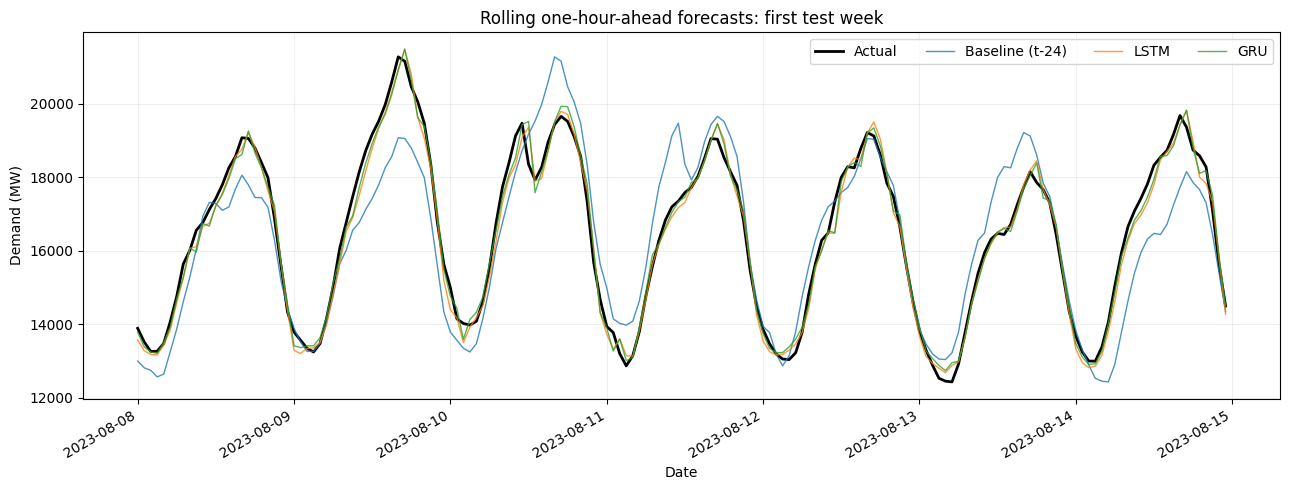

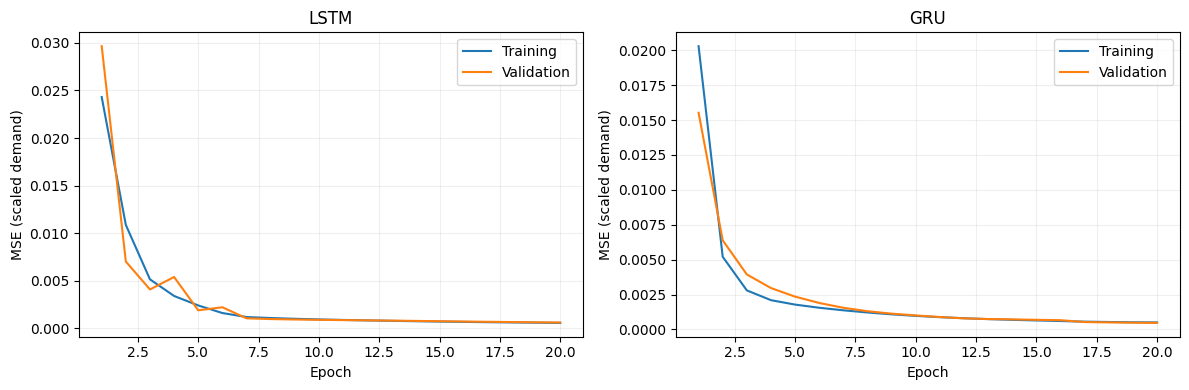

Epochs run: {'LSTM': 20, 'GRU': 20}


In [7]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(test_times[:168], actual[:168], label="Actual", color="black", linewidth=2)
for name, pred in predictions.items():
    ax.plot(test_times[:168], pred[:168], label=name, alpha=0.8, linewidth=1)
ax.set(title="Rolling one-hour-ahead forecasts: first test week", ylabel="Demand (MW)", xlabel="Date")
ax.legend(ncol=4)
ax.grid(alpha=0.2)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig("results/test_week.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, history) in zip(axes, histories.items()):
    epochs = range(1, len(history["loss"]) + 1)
    ax.plot(epochs, history["loss"], label="Training")
    ax.plot(epochs, history["val_loss"], label="Validation")
    ax.set(title=name, xlabel="Epoch", ylabel="MSE (scaled demand)")
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig("results/training_loss.png", dpi=150)
plt.show()
print("Epochs run:", {name: len(h["loss"]) for name, h in histories.items()})

## Notes
This small experiment uses demand history only. Weather, holidays and calendar features could improve forecasts. One chronological test period cannot establish that a model will always perform best; random seeds and deterministic operations reduce run-to-run variation on the same software/hardware.